## ROBOTICA - PARCIAL 2026-2

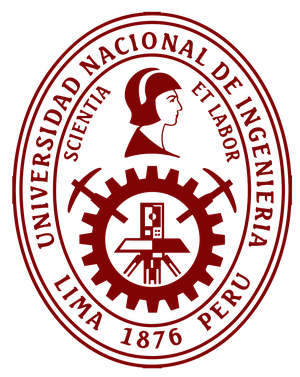


Alumno: Lopez Arteaga, Cesar Omar

Codigo: 20215508C

---

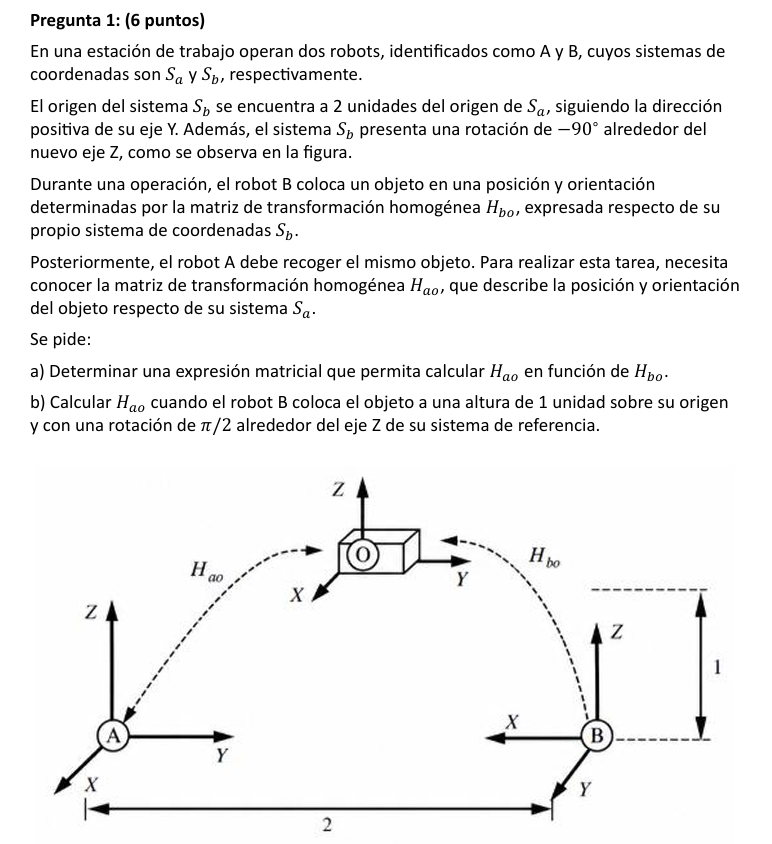

**a)** La composición de transformaciones homogéneas da

$$
H_{ao}=H_{ab}\,H_{bo}, \qquad
H_{ab}=T_y(2)\,R_z(-90^\circ).
$$

In [30]:
import numpy as np
from fquad import *
from homo4 import *
np.set_printoptions(precision=4,suppress=True)

# parte a
print("\n#######   PARTE A    ######")
Hab = T4(0, 2, 0) @ Rz4(-90)
print("Matriz homogénea Hab (del sistema B respecto de A):")
print(Hab)
print("\nExpresión general: Hao = Hab @ Hbo")

# parte b
print("\n#######   PARTE B    ######")
H1=T4(0,2,0)
H2=Rz4(-90)
print("\nH1:",H1)
print("\nH2:",H2)
H3=T4(0,0,1)
H4=Rz4(90)
Hb0=H3@H4

Ha0=H1@H2@Hb0
print("\nMatriz homogenea Ha0=")
print(Ha0)



#######   PARTE A    ######
Matriz homogénea Hab (del sistema B respecto de A):
[[ 0.  1.  0.  0.]
 [-1.  0.  0.  2.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]

Expresión general: Hao = Hab @ Hbo

#######   PARTE B    ######

H1: [[1 0 0 0]
 [0 1 0 2]
 [0 0 1 0]
 [0 0 0 1]]

H2: [[ 0.  1.  0.  0.]
 [-1.  0.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]

Matriz homogenea Ha0=
[[1. 0. 0. 0.]
 [0. 1. 0. 2.]
 [0. 0. 1. 1.]
 [0. 0. 0. 1.]]


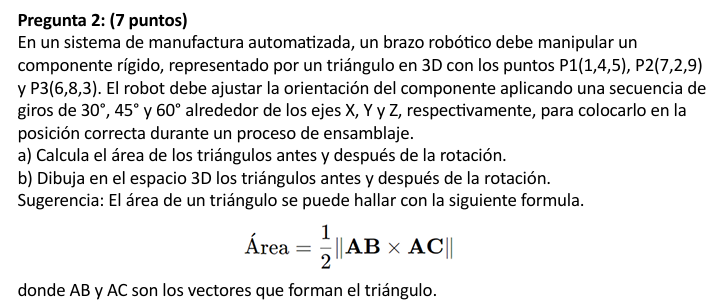

Se consideran giros activos sucesivos en **ejes fijos** $(X,Y,Z)$. Por ello,
si los vectores son columnas, la matriz que los aplica en ese orden es
$R=R_z(60^\circ)R_y(45^\circ)R_x(30^\circ)$

######## PARTE A  ##########
matriz homogenera final H=
[[ 0.3536 -0.5732  0.7392  0.    ]
 [ 0.6124  0.7392  0.2803  0.    ]
 [-0.7071  0.3536  0.6124  0.    ]
 [ 0.      0.      0.      1.    ]]

#####   PARA EL SISTEMA ANTES DE ROTAR   #######
Vector AB= [ 6 -2  4]
Vector AC= [ 5  4 -2]
El producto vectorial de [ 6 -2  4] y [ 5  4 -2] es:
 [-12  32  34]
Area inicial usando vectores iniciales AB y AC = 24.104 

######  PARA EL SISTEMA DESPUES DE ROTAR  #######
Coordenadas de los vértices rotados:
P1' = [1.7567 4.9708 3.769 ]
P2' = [7.9812 8.288  1.2687]
P3' = [-0.2469 10.4288  0.4229]
Vector AB en el nuevo sistema = [ 6.2246  3.3172 -2.5003]
Vector Ac en el nuevo sistema = [-2.0035  5.458  -3.3461]
El producto vectorial de [ 6.2246  3.3172 -2.5003] y [-2.0035  5.458  -3.3461] es:
 [ 2.547  25.8371 40.6197]
Area entre los vectores AB y AC usando nuevo sistema = 24.104 

######## PARTE B  ##########


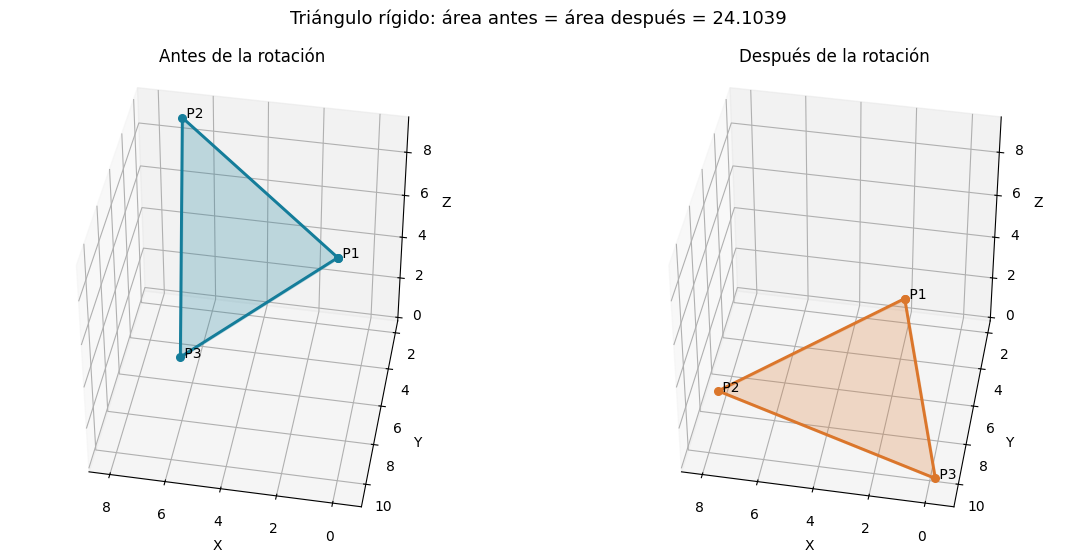

In [37]:

# problema 2
import numpy as np
from fquad import *
from homo4 import *
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
np.set_printoptions(precision=4,suppress=True)

# parte a
print("######## PARTE A  ##########")
p1=np.array([1, 4, 5])# punto  A
p2=np.array([7, 2, 9])# punto B
p3=np.array([6, 8, 3])# punto C

H1=Rx4(30)
H2=Ry4(45)
H3=Rz4(60)

print("matriz homogenera final H=")
H=H3@H2@H1
print(H)
Hinv=np.linalg.inv(H)

print("\n#####   PARA EL SISTEMA ANTES DE ROTAR   #######")
#vector inicial del triangulo
ABini=p2-p1
ACini=p3-p1
print("Vector AB=",ABini)
print("Vector AC=",ACini)
# Calcula el producto vectorial
producto_vectorial = np.cross(ABini, ACini)
print("El producto vectorial de", ABini, "y", ACini, "es:\n", producto_vectorial)
# calculo del area inicial
Area_Inicial=np.linalg.norm(producto_vectorial)/2
print(f"Area inicial usando vectores iniciales AB y AC = {Area_Inicial:.3f} ")

print("\n######  PARA EL SISTEMA DESPUES DE ROTAR  #######")
# Los PUNTOS usan coordenada homogénea 1; los vectores AB/AC usarían 0.
puntos_ini=np.vstack([p1,p2,p3])
puntos_h=np.column_stack((puntos_ini,np.ones(3)))
puntos_fin_h=(H@puntos_h.T).T
puntos_fin=puntos_fin_h[:,:3]
p1fin,p2fin,p3fin=puntos_fin
ABfin=p2fin-p1fin
ACfin=p3fin-p1fin

print("Coordenadas de los vértices rotados:")
for i, punto in enumerate(puntos_fin, start=1):
    print(f"P{i}' =", punto)
print("Vector AB en el nuevo sistema =",ABfin)
print("Vector Ac en el nuevo sistema =",ACfin)

# Calcula el producto vectorial
producto_vectorial_r = np.cross(ABfin, ACfin)
print("El producto vectorial de", ABfin, "y", ACfin, "es:\n", producto_vectorial_r)
# calculo del area inicial
Area_final=np.linalg.norm(producto_vectorial_r)/2
print(f"Area entre los vectores AB y AC usando nuevo sistema = {Area_final:.3f} ")

# parte b
print("\n######## PARTE B  ##########")
# Dibujamos los triángulos en 3D con la misma escala en ambos gráficos.
fig=plt.figure(figsize=(12,5.5))
todos=np.vstack((puntos_ini,puntos_fin))
centro=(todos.min(axis=0)+todos.max(axis=0))/2
radio=0.57*np.max(np.ptp(todos,axis=0))

for num, (vertices, titulo, color) in enumerate([
        (puntos_ini, "Antes de la rotación", "#147d9a"),
        (puntos_fin, "Después de la rotación", "#db762b")], start=1):
    ax=fig.add_subplot(1,2,num,projection="3d")
    poligono=Poly3DCollection([vertices],alpha=0.24,
                             facecolor=color,edgecolor=color,linewidth=2)
    ax.add_collection3d(poligono)
    contorno=np.vstack((vertices,vertices[0]))
    ax.plot(contorno[:,0],contorno[:,1],contorno[:,2],
            "o-",color=color,lw=2.1,markersize=5.5)
    for i,(x,y,z) in enumerate(vertices,start=1):
        ax.text(x,y,z,f" P{i}",fontsize=10)
    ax.set(xlabel="X",ylabel="Y",zlabel="Z",title=titulo)
    ax.set_xlim(centro[0]-radio,centro[0]+radio)
    ax.set_ylim(centro[1]-radio,centro[1]+radio)
    ax.set_zlim(centro[2]-radio,centro[2]+radio)
    ax.set_box_aspect((1,1,1))
    # Vista oblicua que muestra el área de ambos triángulos (evita ver el segundo de canto).
    ax.view_init(elev=42,azim=100)

fig.suptitle(f"Triángulo rígido: área antes = área después = {Area_Inicial:.4f}",fontsize=13)
plt.tight_layout()
plt.show()



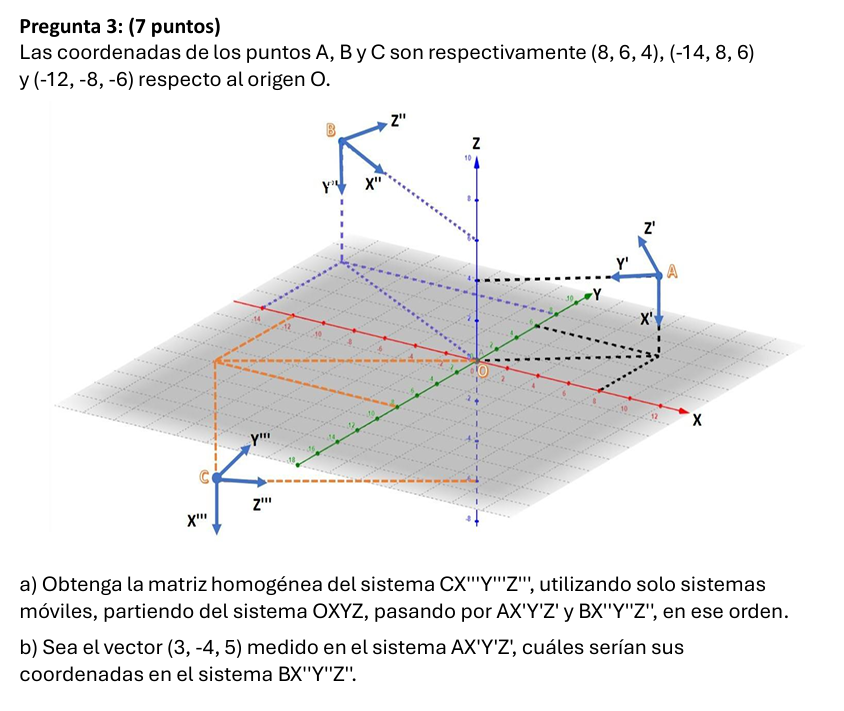

In [ ]:
# problema 3
import numpy as np
from fquad import *
from homo4 import *
np.set_printoptions(precision=4, suppress=True)


A = np.array([8, 6, 4])
B = np.array([-14, 8, 6])
C = np.array([-12, -8, -6])

# parte a
# Usamos ejes MÓVILES: las matrices se multiplican por la derecha.
# X' mira hacia abajo (-Z), Y' apunta hacia O en el plano XY.
# El ángulo exacto es atan2(-8,-6) = -126.8699 grados

print("########   PARTE A  #########")
H1 = T4(8, 6, 4)
H2 = Ry4(90)
H3 = Rx4(np.atan2(-8,-6)*(180/np.pi))

# Paso 1: del sistema OXYZ al sistema AX'Y'Z'.
H_OA = H1 @ H2 @ H3
R_OA = H_OA[:3,:3]

# Orientación de B leída en 3D: Y''=-Z y X'' mira hacia O en el plano XY
# Esta dirección es (-Bx,-By,0)=(14,-8,0)
angulo_B = np.rad2deg(np.arctan2(-B[1], -B[0]))
H_OB_referencia = T4(*B) @ Rz4(angulo_B) @ Rx4(-90)
R_OB_referencia = H_OB_referencia[:3,:3]

# Paso 2: desplazamiento y rotación A -> B expresados en los ejes moviles de A
desplazamiento_AB_A = R_OA.T @ (B-A)
rotacion_AB_A = R_OA.T @ R_OB_referencia
H_AB = T4(*desplazamiento_AB_A)
H_AB[:3,:3] = rotacion_AB_A
H_OB = H_OA @ H_AB
R_OB = H_OB[:3,:3]

# Orientacion de C leída en 3D: X'''=-Z y Z''' mira hacia O en el plano XY
# Su angulo respecto al eje movil X''' es atan2(-8,12)=-33.6901 grados
angulo_C = np.rad2deg(np.arctan2(C[1], -C[0]))
H_OC_referencia = T4(*C) @ Ry4(90) @ Rx4(angulo_C)
R_OC_referencia = H_OC_referencia[:3,:3]

# Paso 3: desplazamiento y rotación B -> C expresados en los ejes moviles de B
desplazamiento_BC_B = R_OB.T @ (C-B)
rotacion_BC_B = R_OB.T @ R_OC_referencia
H_BC = T4(*desplazamiento_BC_B)
H_BC[:3,:3] = rotacion_BC_B

# Composición en el orden exigido: O -> A -> B -> C.
H_OC = H_OA @ H_AB @ H_BC
angulo_A = np.rad2deg(np.arctan2(-A[0], -A[1]))
print("Ángulo de A :", angulo_A)
print("Ángulos de B y C:", angulo_B, "y", angulo_C, "grados")

print("Transformación O -> A:\n", H_OA)
print("\nTraslación A -> B en coordenadas de A:", desplazamiento_AB_A)

print("Transformación A -> B:\n", H_AB)
print("\nTraslación B -> C en coordenadas de B:", desplazamiento_BC_B)

print("Transformación B -> C:\n", H_BC)
print("\nMatriz homogénea pedida del sistema C respecto a O:\n", H_OC)


# parte b
print("\n########   PARTE B  #########")
v_A = np.array([3,-4,5])
# Es un VECTOR, no la posicion de un punto: solo cambia su base de representacion
# v_A = R_AB @ v_B  =>  v_B = R_AB.T @ v_A
R_AB = H_AB[:3,:3]
v_B = R_AB.T @ v_A
print("\nVector (3, -4, 5) en el sistema B:", v_B)


########   PARTE A  #########
Ángulo de A : -126.86989764584402
Ángulos de B y C: -29.74488129694222 y -33.690067525979785 grados
Transformación O -> A:
 [[ 0.  -0.8 -0.6  8. ]
 [ 0.  -0.6  0.8  6. ]
 [-1.  -0.  -0.   4. ]
 [ 0.   0.   0.   1. ]]

Traslación A -> B en coordenadas de A: [-2.  16.4 14.8]
Transformación A -> B:
 [[ 0.      1.     -0.     -2.    ]
 [-0.3969 -0.     -0.9179 16.4   ]
 [-0.9179  0.      0.3969 14.8   ]
 [ 0.      0.      0.      1.    ]]

Traslación B -> C en coordenadas de B: [  9.6747  12.     -12.8996]
Transformación B -> C:
 [[  0.      -0.8944   0.4472   9.6747]
 [  1.       0.       0.      12.    ]
 [ -0.       0.4472   0.8944 -12.8996]
 [  0.       0.       0.       1.    ]]

Matriz homogénea pedida del sistema C respecto a O:
 [[  0.      -0.5547   0.8321 -12.    ]
 [ -0.       0.8321   0.5547  -8.    ]
 [ -1.      -0.       0.      -6.    ]
 [  0.       0.       0.       1.    ]]

########   PARTE B  #########

Vector (3, -4, 5) en el sistema B: [-3